# 11 - Pathway analysis

In [1]:
from sklearn.linear_model import LogisticRegression

In [2]:
import pandas as pd
import numpy as np
import os
from LEAPdata import get_slide_id, get_leap_ids

In [3]:
import glob

In [ ]:
segment = 'CD45+'
input_path = '../patches/treatment_response/ECT/SLIDE_8_LEAP018'
patch_paths = glob.glob(os.path.join(input_path,'*.png'))

In [5]:
train = True
if not train:
    print("infer")
else:
    print("training")

training


Read in metadata

In [7]:
contamination_genes = ['IGHG3',
 'IGHG1',
 'IGHG4',
 'IGHG2',
 'IGKC',
 'IGLL5',
 'IGHM',
 'IGHA1',
 'JCHAIN',
 'MZB1']

In [8]:
SUPTITLESIZE=18
TITLESIZE=16
LABELSIZE=14
NOTESIZE=10

In [ ]:
OME_LEVEL = 2 # should be level 1 but haven't extracted at 20x yet
DOWNSAMPLE = 2**OME_LEVEL

root_path = "../data"
metadata_path = os.path.join(root_path,'01-raw','metadata')
feature_path = os.path.join(root_path,'02-input','features')
outcome_path = os.path.join(root_path,'02-input','outcomes')
summary_path = os.path.join(root_path,'03-results_cv','summary')
output_path = os.path.join(root_path,'05-pathway_analysis')
gene_path = os.path.join(output_path,'genes')

exp_name = 'retrain_final_models_2026-02-28_1053'
input_path = os.path.join(root_path,'04-results_test',exp_name)
gene_path = input_path
folder_name = 'rerun_fixed'

# Pathway Analysis

In [10]:
import gseapy as gp

In [11]:
import matplotlib.pyplot as plt

## Load gene lists

In [12]:
all_scores = pd.read_csv(os.path.join(gene_path,'combined-svm-genescores.csv'))
all_scores.head()

,GeneSet,Segment,Feature_Extractor,Model,Gene,MSE,RMSE,nRMSE,MAE,R2,PearsonCorr,PearsonPVals,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,SpearmanPVals,SpearmanQVals,VarianceRatio,ConcordanceCorr
0,Panel,CD45+,combined,SVM,CD274,0.488187,0.698704,0.638821,0.578241,0.588720,0.785891,2.753326e-28,9.636640e-28,0.709406,0.844081,0.753096,7.533441e-25,1.757803e-24,0.451949,0.719826
1,Panel,CD45+,combined,SVM,CXCL9,1.127880,1.062017,0.647939,0.780332,0.576895,0.766254,3.678143e-26,8.582333e-26,0.683995,0.829271,0.749172,1.787575e-24,3.575150e-24,0.625107,0.741183
2,Panel,CD45+,combined,SVM,IFNG,0.517009,0.719033,0.763229,0.576721,0.412931,0.651709,6.064506e-17,6.531006e-17,0.539646,0.741080,0.635591,5.893896e-16,6.347273e-16,0.444594,0.596838
3,Panel,CD45+,combined,SVM,BCL2,0.531401,0.728973,0.613634,0.576364,0.620511,0.800630,4.918093e-30,6.885331e-29,0.728609,0.855139,0.772870,7.468071e-27,3.485100e-26,0.496555,0.748323
4,Panel,CD45+,combined,SVM,CD3D,0.590856,0.768672,0.646500,0.580919,0.578773,0.780891,1.004305e-27,2.812054e-27,0.702917,0.840319,0.773819,5.916562e-27,3.485100e-26,0.532665,0.730169


drop duplicate genes

In [13]:
all_scores

,GeneSet,Segment,Feature_Extractor,Model,Gene,MSE,RMSE,nRMSE,MAE,R2,PearsonCorr,PearsonPVals,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,SpearmanPVals,SpearmanQVals,VarianceRatio,ConcordanceCorr
0,Panel,CD45+,combined,SVM,CD274,0.488187,0.698704,0.638821,0.578241,0.588720,0.785891,2.753326e-28,9.636640e-28,0.709406,0.844081,0.753096,7.533441e-25,1.757803e-24,0.451949,0.719826
1,Panel,CD45+,combined,SVM,CXCL9,1.127880,1.062017,0.647939,0.780332,0.576895,0.766254,3.678143e-26,8.582333e-26,0.683995,0.829271,0.749172,1.787575e-24,3.575150e-24,0.625107,0.741183
2,Panel,CD45+,combined,SVM,IFNG,0.517009,0.719033,0.763229,0.576721,0.412931,0.651709,6.064506e-17,6.531006e-17,0.539646,0.741080,0.635591,5.893896e-16,6.347273e-16,0.444594,0.596838
3,Panel,CD45+,combined,SVM,BCL2,0.531401,0.728973,0.613634,0.576364,0.620511,0.800630,4.918093e-30,6.885331e-29,0.728609,0.855139,0.772870,7.468071e-27,3.485100e-26,0.496555,0.748323
4,Panel,CD45+,combined,SVM,CD3D,0.590856,0.768672,0.646500,0.580919,0.578773,0.780891,1.004305e-27,2.812054e-27,0.702917,0.840319,0.773819,5.916562e-27,3.485100e-26,0.532665,0.730169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,SVG,PanCK+,combined,SVM,BLNK,0.879384,0.937755,0.833976,0.731561,0.300191,0.563651,4.744257e-15,1.367462e-14,0.448819,0.660171,0.565366,3.763032e-15,1.418374e-14,0.292665,0.465657
215,SVG,PanCK+,combined,SVM,NWD2,0.800793,0.894871,0.810031,0.682033,0.339799,0.639408,4.077556e-20,9.990013e-19,0.538630,0.722148,0.641975,2.592025e-20,4.233641e-19,0.390407,0.547572
216,SVG,PanCK+,combined,SVM,RPS12,1.191799,1.091696,0.838555,0.835866,0.292485,0.565185,3.856720e-15,1.181120e-14,0.450614,0.661439,0.527129,4.875928e-13,1.137717e-12,0.209953,0.422653
217,SVG,PanCK+,combined,SVM,RPL12,1.232499,1.110180,0.877144,0.821896,0.225869,0.541881,8.027591e-14,1.966760e-13,0.423432,0.642115,0.536352,1.594890e-13,3.907482e-13,0.201220,0.385747


In [14]:
all_scores = all_scores.drop_duplicates(subset=['Segment','Gene'])


In [15]:
all_scores[all_scores.duplicated('Gene', keep=False)].sort_values('Gene')

,GeneSet,Segment,Feature_Extractor,Model,Gene,MSE,RMSE,nRMSE,MAE,R2,PearsonCorr,PearsonPVals,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,SpearmanPVals,SpearmanQVals,VarianceRatio,ConcordanceCorr
50,HVG,CD45+,combined,SVM,AARD,0.574191,0.757754,0.752939,0.613238,0.428654,0.679489,8.569378e-19,1.749581e-18,0.574059,0.762756,0.679787,8.166014e-19,1.905403e-18,0.504662,0.628213
151,HVG,PanCK+,combined,SVM,AARD,1.320188,1.148994,1.012941,0.907669,-0.032384,0.538988,1.151462e-13,3.382420e-13,0.420072,0.639707,0.523784,7.252223e-13,1.893636e-12,0.505803,0.426147
134,HVG,PanCK+,combined,SVM,ACTG2,1.564850,1.250940,1.037166,1.015604,-0.082354,0.200305,1.035689e-02,1.106304e-02,0.048065,0.343450,0.214819,5.891756e-03,6.439827e-03,0.277242,0.163101
31,HVG,CD45+,combined,SVM,ACTG2,0.545889,0.738843,0.762821,0.626485,0.413558,0.656360,3.066099e-17,5.365674e-17,0.545382,0.744722,0.603996,3.522162e-14,4.931027e-14,0.281255,0.542780
76,SVG,CD45+,combined,SVM,ADAM15,1.388683,1.178424,0.681746,0.969366,0.531592,0.735580,3.163394e-23,5.272323e-23,0.644698,0.805958,0.707274,7.375999e-21,1.152500e-20,0.693721,0.723447
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,Panel,CD45+,combined,SVM,S100A9,1.088873,1.043491,0.809962,0.797561,0.338837,0.631429,1.037695e-15,1.037695e-15,0.514758,0.725138,0.618261,5.881631e-15,5.881631e-15,0.765498,0.625631
64,SVG,CD45+,combined,SVM,SUPT7L,1.170322,1.081814,0.723812,0.897719,0.472003,0.709181,5.214973e-21,7.243018e-21,0.611258,0.785718,0.731344,7.473904e-23,1.437289e-22,0.633963,0.681416
175,SVG,PanCK+,combined,SVM,SUPT7L,1.066913,1.032915,0.902689,0.846497,0.180123,0.617667,1.603361e-18,1.571294e-17,0.512618,0.704497,0.672027,9.190195e-23,4.503196e-21,0.573528,0.532944
177,SVG,PanCK+,combined,SVM,TMEM106C,1.169357,1.081368,1.012433,0.846613,-0.031348,0.353227,3.746568e-06,4.079596e-06,0.210961,0.480839,0.317847,3.557160e-05,3.873352e-05,0.556778,0.338238


Identify our list of strongly predicted genes:
 - R2 > 0.2
 - PCC > 0.5
 - qval < 0.05>

use only genes over PCC threshold
what if we try over 0.45

In [16]:
cond = (all_scores['R2'] > 0.2)  # coefficient of determination
cond = cond & (all_scores['PearsonCorr'] > 0.45) # Pearson's Rho (Correlation coefficient)
cond = cond & (all_scores['PearsonQVals'] < 0.05) # FDR-adjusted p-value of Pearson Correlation
all_scores[cond]

,GeneSet,Segment,Feature_Extractor,Model,Gene,MSE,RMSE,nRMSE,MAE,R2,PearsonCorr,PearsonPVals,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,SpearmanPVals,SpearmanQVals,VarianceRatio,ConcordanceCorr
0,Panel,CD45+,combined,SVM,CD274,0.488187,0.698704,0.638821,0.578241,0.588720,0.785891,2.753326e-28,9.636640e-28,0.709406,0.844081,0.753096,7.533441e-25,1.757803e-24,0.451949,0.719826
1,Panel,CD45+,combined,SVM,CXCL9,1.127880,1.062017,0.647939,0.780332,0.576895,0.766254,3.678143e-26,8.582333e-26,0.683995,0.829271,0.749172,1.787575e-24,3.575150e-24,0.625107,0.741183
2,Panel,CD45+,combined,SVM,IFNG,0.517009,0.719033,0.763229,0.576721,0.412931,0.651709,6.064506e-17,6.531006e-17,0.539646,0.741080,0.635591,5.893896e-16,6.347273e-16,0.444594,0.596838
3,Panel,CD45+,combined,SVM,BCL2,0.531401,0.728973,0.613634,0.576364,0.620511,0.800630,4.918093e-30,6.885331e-29,0.728609,0.855139,0.772870,7.468071e-27,3.485100e-26,0.496555,0.748323
4,Panel,CD45+,combined,SVM,CD3D,0.590856,0.768672,0.646500,0.580919,0.578773,0.780891,1.004305e-27,2.812054e-27,0.702917,0.840319,0.773819,5.916562e-27,3.485100e-26,0.532665,0.730169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,SVG,PanCK+,combined,SVM,BLNK,0.879384,0.937755,0.833976,0.731561,0.300191,0.563651,4.744257e-15,1.367462e-14,0.448819,0.660171,0.565366,3.763032e-15,1.418374e-14,0.292665,0.465657
215,SVG,PanCK+,combined,SVM,NWD2,0.800793,0.894871,0.810031,0.682033,0.339799,0.639408,4.077556e-20,9.990013e-19,0.538630,0.722148,0.641975,2.592025e-20,4.233641e-19,0.390407,0.547572
216,SVG,PanCK+,combined,SVM,RPS12,1.191799,1.091696,0.838555,0.835866,0.292485,0.565185,3.856720e-15,1.181120e-14,0.450614,0.661439,0.527129,4.875928e-13,1.137717e-12,0.209953,0.422653
217,SVG,PanCK+,combined,SVM,RPL12,1.232499,1.110180,0.877144,0.821896,0.225869,0.541881,8.027591e-14,1.966760e-13,0.423432,0.642115,0.536352,1.594890e-13,3.907482e-13,0.201220,0.385747


### CD45+

In [17]:
best_genes_cd45 = list(all_scores.loc[(all_scores['Segment']=='CD45+')& cond,:].sort_values('PearsonCorr',ascending=False)['Gene'])
worst_genes_cd45 = list(all_scores.loc[(all_scores['Segment']=='CD45+')& ~cond,:].sort_values('PearsonCorr')['Gene'])

These are taken from our results on the whole training set

In [18]:
# ############ R2 > 0.2 threshold ############
best_genes_cd45_virchow = ['FDCSP','ST6GALNAC3','AREG','TARP','CPB1','C7','P2RY12','BCL2','TENT5C',
                           'IDO1','PITX1','STAT1','DMRTC1B','RPL41','UBE2E1','TAPBP','RPL26','CCSAP',
                           'CD274','IFITM1','CD3D','GABRP','REPS2','RPLP1','PIP','IGHA1','PRMT8','CXCL9',
                           'IGLL5','CD163','USP17L3','CD8A','CD82','IFNG','IGHG2','IGHG1','IGHG3','ISG15',
                           'HLA-B','CXCL14','NFKB2','GPR135','NDOR1','MX1','IGHG4','HLA-E','LAG3','SMR3A',
                           'RPS20','S100A1','IGHM','IGKC','FXYD3','FOXP3','CD68','JCHAIN','C1QL2','BOD1L2',
                           'TRPM3','EYA2','KRT7','CALML5','KRT5','CRABP2','CD4','ADAM15','AARD','FABP7',
                           'TMEM106C','MUCL1','TPSAB1','APOC1','KRT14','ACTG2','CCL24','IFI6','KRT6A','LCN2',
                           'SFRP1','KRT23','ZFP57','APOE','MMP1','APOD','SERPINA3','S100A9','PPP2R2B','MMP11',
                           'SUPT7L','COL1A1','MMP7','KRT17','ELN','KRT15','S100A7','CRABP1']


    
worst_genes_cd45_virchow = ['MGP','MZT2B','FNTB','HLA-DQA1']



These genes were good in the Virchow-SVM model but not combined-SVM

In [19]:
set(best_genes_cd45_virchow).difference(set(best_genes_cd45))

{'MMP7', 'MUCL1', 'SERPINA3', 'ZFP57'}

These genes were good in the combined-SVM model but not Virchow-SVM

In [20]:
set(best_genes_cd45).difference(set(best_genes_cd45_virchow))

{'ELF5'}

### PanCK+

In [21]:
best_genes_panck = list(all_scores.loc[(all_scores['Segment']=='PanCK+')& cond,:].sort_values('PearsonCorr',ascending=False)['Gene'])
worst_genes_panck = list(all_scores.loc[(all_scores['Segment']=='PanCK+')& ~cond,:].sort_values('PearsonCorr')['Gene'])

In [22]:
############ R2 > 0.2 threshold ############
best_genes_panck_uni = ['BRINP3','ENO1','EGFR','CA9',
                        'S100P','ATP5MC2','SNAI1','BRCA2','DMRTB1','PIK3CA','PTEN',
                        'RNF126','CHI3L1','RB1','LTF','FTH1','NWD2','S100A2','BRCA1','PTBP1',
                        'MMP9','UBD','ALDH1A1','CSN3','SLC2A4RG','FABP7','CPB1','ALDOA','CXCL1','C11orf58',]

worst_genes_panck_uni = ['MMP7','ELN','SOX10','CRABP1','MYC','HLA-A','IRX1','FDCSP','SCGB2A2',
                         'HLA-F','KRT6A','AARD','GABRP','AQP3','FABP5','ACTG2','TP53','MGP','VIM',
                         'KLK5','TMA7','LCN2','KRT14','HLA-B','CCL28','ISG15']



These genes were good in UNI-SVM but not combined-SVM

In [23]:
set(best_genes_panck_uni).difference(set(best_genes_panck))

{'CHI3L1', 'MMP9', 'PTBP1', 'UBD'}

## Evaluate Significant PAthways

save the top 20 genes in each segment


In [26]:
cond = (all_scores['R2'] > 0.2)  # coefficient of determination
cond = cond & (all_scores['PearsonCorr'] > 0.5) # Pearson's Rho (Correlation coefficient)
cond = cond & (all_scores['PearsonQVals'] < 0.05) # FDR-adjusted p-value of Pearson Correlation
all_scores =  all_scores.sort_values(by=['PearsonCorr'],ascending=False)
top_genes_cd45 = list(all_scores.loc[(all_scores['Segment']=='CD45+')& cond,'Gene'].head(20))
top_genes_panck = list(all_scores.loc[(all_scores['Segment']=='PanCK+')& cond,'Gene'].head(20))

In [27]:
all_scores[(all_scores['Segment']=='PanCK+')].head()

,GeneSet,Segment,Feature_Extractor,Model,Gene,MSE,RMSE,nRMSE,MAE,R2,PearsonCorr,PearsonPVals,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,SpearmanPVals,SpearmanQVals,VarianceRatio,ConcordanceCorr
104,Panel,PanCK+,combined,SVM,BRCA1,0.918943,0.958615,0.827705,0.744292,0.310675,0.666250,2.860372e-22,6.578856e-21,0.571010,0.743794,0.689170,2.706618e-24,6.225222e-23,0.466996,0.569150
200,SVG,PanCK+,combined,SVM,ENO1,1.301938,1.141025,0.784483,0.883800,0.380788,0.661253,7.484185e-22,3.667250e-20,0.564960,0.739777,0.647001,1.054310e-20,2.583060e-19,0.185398,0.479065
143,HVG,PanCK+,combined,SVM,S100A2,1.404009,1.184909,0.764966,0.929056,0.411215,0.647915,8.935757e-21,4.199806e-19,0.548859,0.729026,0.624084,5.588511e-19,8.755334e-18,0.397438,0.581148
105,Panel,PanCK+,combined,SVM,BRCA2,0.893169,0.945076,0.784013,0.748609,0.381529,0.641248,2.948375e-20,3.390631e-19,0.540839,0.723637,0.636901,6.320911e-20,3.634524e-19,0.361321,0.554858
215,SVG,PanCK+,combined,SVM,NWD2,0.800793,0.894871,0.810031,0.682033,0.339799,0.639408,4.077556e-20,9.990013e-19,0.538630,0.722148,0.641975,2.592025e-20,4.233641e-19,0.390407,0.547572


In [ ]:
libraries=["MSigDB_Hallmark_2020", 
           "Reactome_Pathways_2024",
           ]


In [ ]:
def check_genesets(bestgenes,worstgenes, libs, segment='CD45+'):
    ## CD45
    best_enrich = gp.enrichr(
        gene_list=bestgenes,
        gene_sets=libs,
        organism='Human',
    )
    best_cd45_df = best_enrich.results.sort_values('Adjusted P-value')
    best_cd45_df.head(10)

    worst_enrich = gp.enrichr(
        gene_list=worstgenes,
        gene_sets=libs,
        organism='Human',
    )
    worst_cd45_df = worst_enrich.results.sort_values('Adjusted P-value')
    worst_cd45_df.head(10)

    return best_cd45_df, worst_cd45_df

In [ ]:
# # ORIGINAL
# def get_significant_pathways(genelist,libraries):
#     best_enrich = gp.enrichr(
#         gene_list=genelist,
#         gene_sets=libraries,
#         organism='Human',
#     )
#     best_df = best_enrich.results.sort_values('Adjusted P-value')
#     best_df = best_df[best_df['Adjusted P-value']<0.05]
#     return best_df

In [ ]:
def get_significant_pathways(genelist,libraries):
    best_enrich = gp.enrichr(
        gene_list=genelist,
        gene_sets=libraries,
        organism='Human',
    )
    df = best_enrich.results.copy()

    # Establish statistical significance first
    df = df[df["Adjusted P-value"] < 0.05]

    # Then prioritise stronger effects
    df = df.sort_values(
        ["Combined Score", "Adjusted P-value"],
        ascending=[False, True]
    )

    return df

use only the best genes

In [32]:
signif_cd45 = get_significant_pathways(best_genes_cd45,libraries)
worst_cd45_df = get_significant_pathways(worst_genes_cd45,libraries)

signif_panck = get_significant_pathways(best_genes_panck,libraries)
worst_panck_df = get_significant_pathways(worst_genes_panck,libraries)

filter out the highest level with the huge geneset sizes

In [33]:
signif_cd45 = signif_cd45[signif_cd45['Overlap'].str.split('/').str[1].astype(int)<=1000]
signif_panck = signif_panck[signif_panck['Overlap'].str.split('/').str[1].astype(int)<=1000]

In [34]:
signif_cd45.head(10)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
25,Reactome_Pathways_2024,Interferon Alpha Beta Signaling,7/78,7.548221e-08,0.000017,0,0,22.740255,372.925838,IFITM1;STAT1;MX1;HLA-B;IFI6;ISG15;HLA-E
0,MSigDB_Hallmark_2020,Allograft Rejection,8/200,4.278954e-06,0.000051,0,0,9.664216,119.467120,CD4;CXCL9;IFNG;STAT1;CD8A;CD3D;TAPBP;HLA-E
1,MSigDB_Hallmark_2020,Interferon Gamma Response,8/200,4.278954e-06,0.000051,0,0,9.664216,119.467120,CD274;CXCL9;STAT1;MX1;HLA-B;ISG15;TAPBP;IDO1
26,Reactome_Pathways_2024,Cytokine Signaling in Immune System,16/776,5.279295e-07,0.000078,0,0,5.234997,75.668227,IFITM1;MMP1;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...
27,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,3/6,1.926978e-06,0.000208,0,0,221.155556,2910.309244,LCN2;S100A9;S100A7
28,Reactome_Pathways_2024,Formation of the Cornified Envelope,7/129,2.356954e-06,0.000208,0,0,13.200057,171.048192,KRT17;KRT15;KRT14;KRT7;KRT23;KRT5;KRT6A
2,MSigDB_Hallmark_2020,KRAS Signaling Dn,7/200,4.124242e-05,0.000330,0,0,8.314134,83.939859,CPB1;IFNG;CALML5;KRT15;MX1;KRT5;TENT5C
30,Reactome_Pathways_2024,Interferon Signaling,9/280,6.257370e-06,0.000394,0,0,7.763310,93.018050,IFITM1;IFNG;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...
32,Reactome_Pathways_2024,Adaptive Immune System,15/854,8.804045e-06,0.000431,0,0,4.370588,50.874949,IGHM;CD274;LAG3;IFITM1;S100A1;UBE2E1;HLA-B;CD3...
33,Reactome_Pathways_2024,Interleukin-4 and Interleukin-13 Signaling,6/112,1.382595e-05,0.000610,0,0,12.882889,144.146171,IGHG4;IGHG1;MMP1;STAT1;BCL2;LCN2


In [ ]:
signif_panck = signif_panck.sort_values(['Adjusted P-value','Odds Ratio'])

# Check the Tissues dataset for tumour

In [37]:
get_significant_pathways(best_genes_panck,"TISSUES_Curated_2025")

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,TISSUES_Curated_2025,KERATINOCYTE,5/134,0.000030,0.002633,0,0,15.675526,163.022565,S100A2;KRT16;PI3;S100A9;TP63
1,TISSUES_Curated_2025,STRATUM SPINOSUM,5/134,0.000030,0.002633,0,0,15.675526,163.022565,S100A2;KRT16;PI3;S100A9;TP63
2,TISSUES_Curated_2025,EPIDERMAL CELL,5/187,0.000148,0.008521,0,0,11.080960,97.733275,S100A2;KRT16;PI3;S100A9;TP63
3,TISSUES_Curated_2025,EPIDERMIS,5/261,0.000684,0.029287,0,0,7.848374,57.199864,S100A2;KRT16;PI3;S100A9;TP63
4,TISSUES_Curated_2025,BREAST,6/414,0.000846,0.029287,0,0,5.985907,42.347126,S100A2;KRT16;FABP7;SNAI1;BRCA1;LTF


# Hallmark & Reactome

In [38]:
signif_cd45_top = get_significant_pathways(top_genes_cd45,libraries)
signif_panck_top = get_significant_pathways(top_genes_panck,libraries)
signif_cd45_top = signif_cd45_top[signif_cd45_top['Overlap'].str.split('/').str[1].astype(int)<=1000]
signif_panck_top = signif_panck_top[signif_panck_top['Overlap'].str.split('/').str[1].astype(int)<=1000]

In [39]:
signif_cd45_top

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
12,Reactome_Pathways_2024,NFE2L2 Regulating Tumorigenic Genes,2/11,0.000052,0.009614,0,0,246.555556,2432.238168,BCL2;AREG
13,Reactome_Pathways_2024,Estrogen-dependent Nuclear Events Downstream o...,2/24,0.000259,0.023936,0,0,100.797980,832.549579,BCL2;AREG


## CD45

In [ ]:
signif_cd45=signif_cd45.sort_values('Adjusted P-value')

In [42]:
cond = signif_cd45['Gene_set'].isin(['MSigDB_Hallmark_2020'])
signif_cd45.loc[cond,['Gene_set','Term','Adjusted P-value','Genes','Overlap']].head()

,Gene_set,Term,Adjusted P-value,Genes,Overlap
0,MSigDB_Hallmark_2020,Allograft Rejection,0.000051,CD4;CXCL9;IFNG;STAT1;CD8A;CD3D;TAPBP;HLA-E,8/200
1,MSigDB_Hallmark_2020,Interferon Gamma Response,0.000051,CD274;CXCL9;STAT1;MX1;HLA-B;ISG15;TAPBP;IDO1,8/200
2,MSigDB_Hallmark_2020,KRAS Signaling Dn,0.000330,CPB1;IFNG;CALML5;KRT15;MX1;KRT5;TENT5C,7/200
5,MSigDB_Hallmark_2020,Inflammatory Response,0.009707,CCL24;CXCL9;IFITM1;CD82;TAPBP,5/200
4,MSigDB_Hallmark_2020,Epithelial Mesenchymal Transition,0.009707,COL1A1;SFRP1;MMP1;ELN;AREG,5/200


In [43]:
cond = signif_cd45['Gene_set'].isin(['Reactome_Pathways_2024'])
signif_cd45.loc[cond,['Gene_set','Term','Adjusted P-value','Genes','Overlap']].head()

,Gene_set,Term,Adjusted P-value,Genes,Overlap
25,Reactome_Pathways_2024,Interferon Alpha Beta Signaling,0.000017,IFITM1;STAT1;MX1;HLA-B;IFI6;ISG15;HLA-E,7/78
26,Reactome_Pathways_2024,Cytokine Signaling in Immune System,0.000078,IFITM1;MMP1;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...,16/776
27,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,0.000208,LCN2;S100A9;S100A7,3/6
28,Reactome_Pathways_2024,Formation of the Cornified Envelope,0.000208,KRT17;KRT15;KRT14;KRT7;KRT23;KRT5;KRT6A,7/129
30,Reactome_Pathways_2024,Interferon Signaling,0.000394,IFITM1;IFNG;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...,9/280


In [46]:
signif_cd45.to_csv(os.path.join(output_path,'SignificantPathways_CD45.csv'))

In [47]:
signif_cd45 = signif_cd45.sort_values('Combined Score', ascending=False)
signif_cd45.head()

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
27,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,3/6,1.926978e-06,0.000208,0,0,221.155556,2910.309244,LCN2;S100A9;S100A7
69,Reactome_Pathways_2024,RUNX1 and FOXP3 Control the Development of Reg...,2/10,9.394885e-04,0.009007,0,0,54.667582,381.042615,IFNG;FOXP3
25,Reactome_Pathways_2024,Interferon Alpha Beta Signaling,7/78,7.548221e-08,0.000017,0,0,22.740255,372.925838,IFITM1;STAT1;MX1;HLA-B;IFI6;ISG15;HLA-E
76,Reactome_Pathways_2024,NFE2L2 Regulating Tumorigenic Genes,2/11,1.144791e-03,0.009108,0,0,48.590965,329.083906,BCL2;AREG
77,Reactome_Pathways_2024,Type I Hemidesmosome Assembly,2/11,1.144791e-03,0.009108,0,0,48.590965,329.083906,KRT14;KRT5


Removing Metal Sequestration as it dominates the plot

In [48]:
drop_terms = ['Metal Sequestration by Antimicrobial Proteins']
drop_term_cond =(~signif_cd45['Term'].isin(drop_terms))

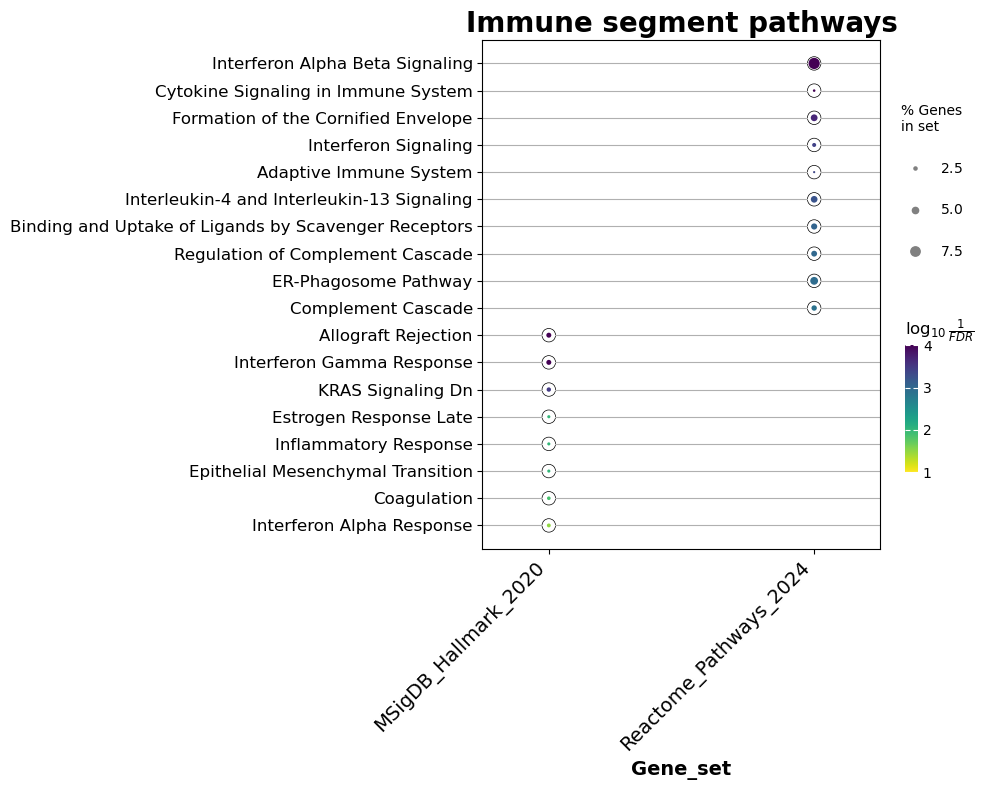

In [49]:
ax = gp.dotplot(signif_cd45[~signif_cd45['Term'].isin(drop_terms)], 
            column="Adjusted P-value", 
            title=f'Immune segment pathways',
            x='Gene_set',
            xticklabels_rot=45, # rotate xtick labels
            top_term=10, 
            size=15,
            show_ring=True,
            
            figsize=(10,8),
            )
ax.tick_params(axis='y', labelsize=12)


plt.tight_layout()
plt.show()

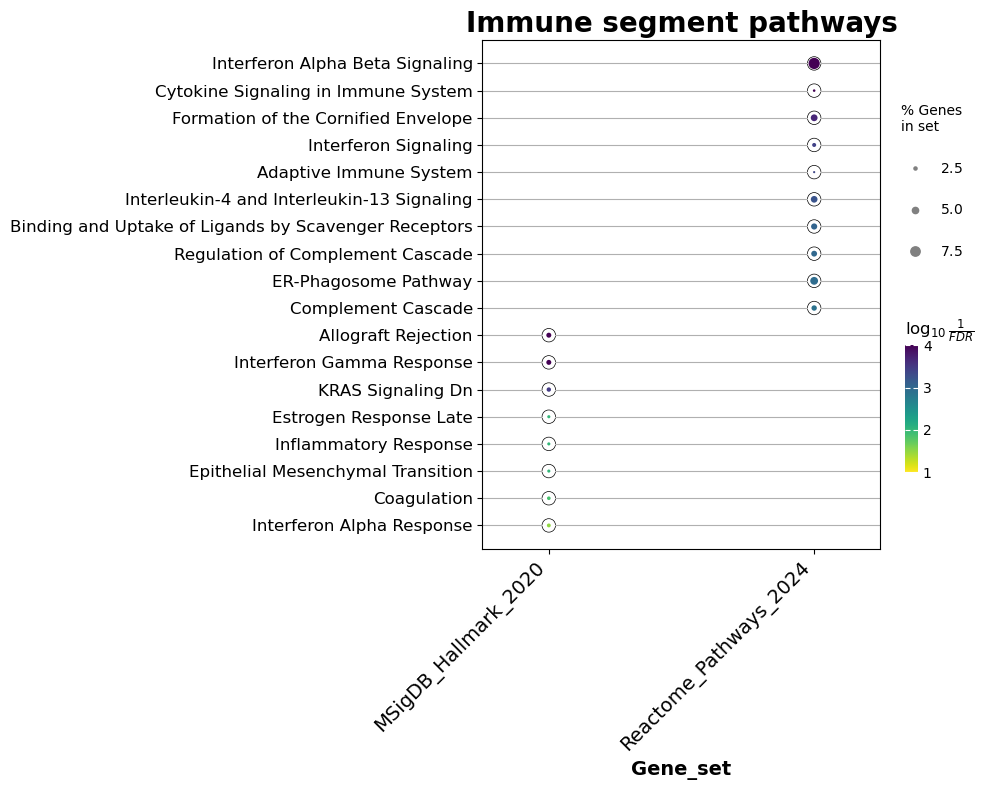

In [50]:
ax = gp.dotplot(signif_cd45[~signif_cd45['Term'].isin(drop_terms)], 
            column="Adjusted P-value", 
            title=f'Immune segment pathways',
            x='Gene_set',
            xticklabels_rot=45, # rotate xtick labels
            top_term=10, 
            size=15,
            show_ring=True,
            
            figsize=(10,8),
            )
ax.tick_params(axis='y', labelsize=12)


plt.tight_layout()
plt.show()

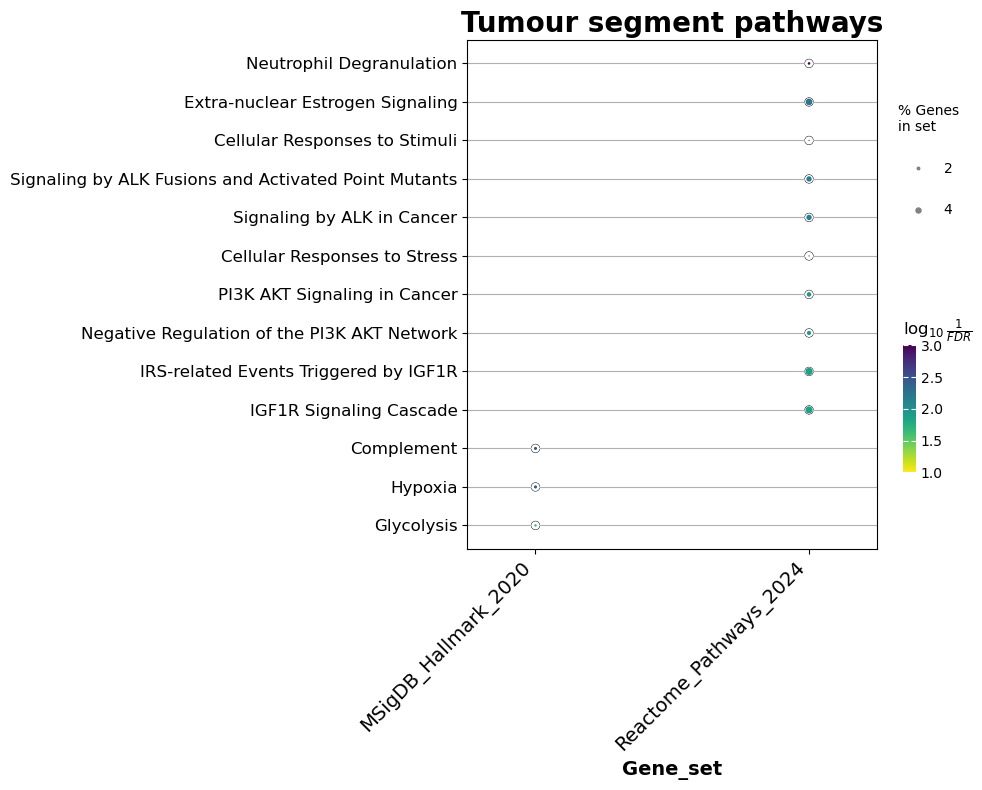

In [51]:
ax = gp.dotplot(signif_panck[~signif_panck['Term'].isin(drop_terms)], 
            column="Adjusted P-value", 
            title=f'Tumour segment pathways',
            x='Gene_set',
            xticklabels_rot=45, # rotate xtick labels
            top_term=10, 
            size=15,
            show_ring=True,
            
            figsize=(10,8),
            )
ax.tick_params(axis='y', labelsize=12)


plt.tight_layout()
plt.show()

In [52]:
signif_cd45.sort_values('Adjusted P-value', ascending=True).head(10)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
25,Reactome_Pathways_2024,Interferon Alpha Beta Signaling,7/78,7.548221e-08,0.000017,0,0,22.740255,372.925838,IFITM1;STAT1;MX1;HLA-B;IFI6;ISG15;HLA-E
1,MSigDB_Hallmark_2020,Interferon Gamma Response,8/200,4.278954e-06,0.000051,0,0,9.664216,119.467120,CD274;CXCL9;STAT1;MX1;HLA-B;ISG15;TAPBP;IDO1
0,MSigDB_Hallmark_2020,Allograft Rejection,8/200,4.278954e-06,0.000051,0,0,9.664216,119.467120,CD4;CXCL9;IFNG;STAT1;CD8A;CD3D;TAPBP;HLA-E
26,Reactome_Pathways_2024,Cytokine Signaling in Immune System,16/776,5.279295e-07,0.000078,0,0,5.234997,75.668227,IFITM1;MMP1;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...
27,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,3/6,1.926978e-06,0.000208,0,0,221.155556,2910.309244,LCN2;S100A9;S100A7
28,Reactome_Pathways_2024,Formation of the Cornified Envelope,7/129,2.356954e-06,0.000208,0,0,13.200057,171.048192,KRT17;KRT15;KRT14;KRT7;KRT23;KRT5;KRT6A
2,MSigDB_Hallmark_2020,KRAS Signaling Dn,7/200,4.124242e-05,0.000330,0,0,8.314134,83.939859,CPB1;IFNG;CALML5;KRT15;MX1;KRT5;TENT5C
30,Reactome_Pathways_2024,Interferon Signaling,9/280,6.257370e-06,0.000394,0,0,7.763310,93.018050,IFITM1;IFNG;STAT1;MX1;IFI6;UBE2E1;HLA-B;ISG15;...
32,Reactome_Pathways_2024,Adaptive Immune System,15/854,8.804045e-06,0.000431,0,0,4.370588,50.874949,IGHM;CD274;LAG3;IFITM1;S100A1;UBE2E1;HLA-B;CD3...
33,Reactome_Pathways_2024,Interleukin-4 and Interleukin-13 Signaling,6/112,1.382595e-05,0.000610,0,0,12.882889,144.146171,IGHG4;IGHG1;MMP1;STAT1;BCL2;LCN2


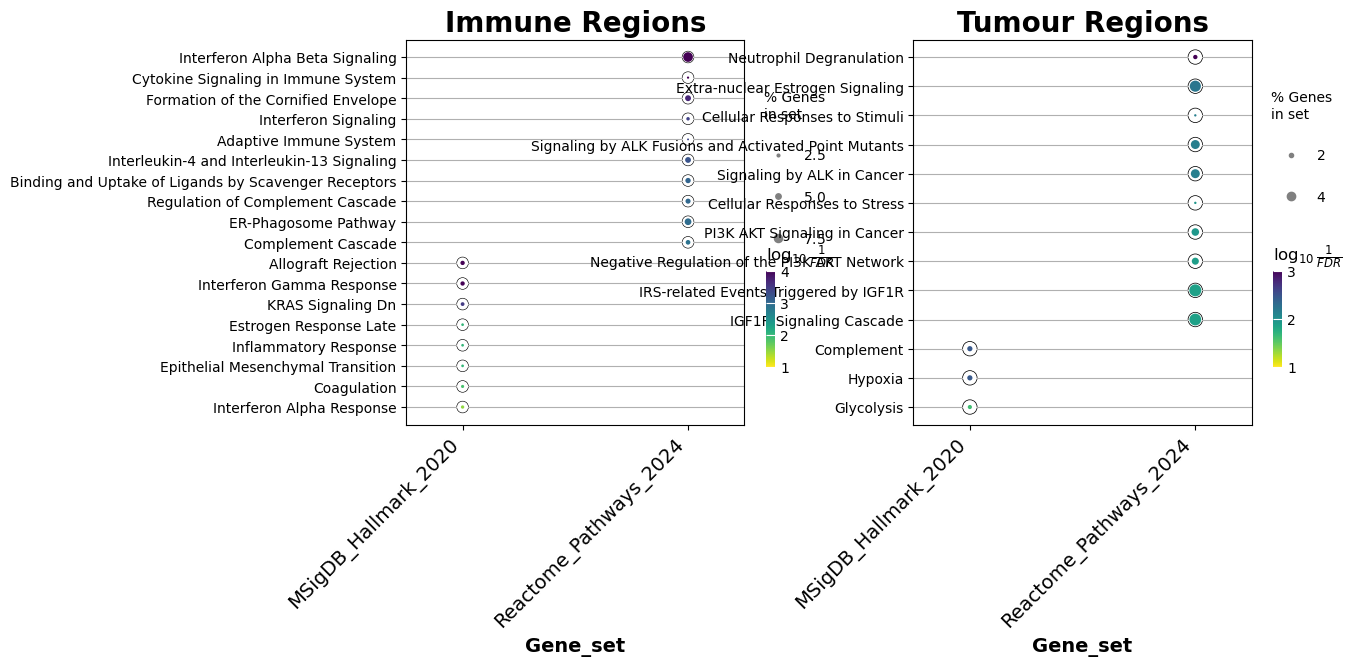

In [53]:
fig, axes = plt.subplots( 1, 2, figsize=(12,5))

gp.dotplot(signif_cd45[~signif_cd45['Term'].isin(drop_terms)], 
            column="Adjusted P-value", 
            title=f'Immune Regions',
            x='Gene_set',
            xticklabels_rot=45, # rotate xtick labels
            top_term=10, 
            size=13,
            show_ring=True,
            #figsize=(6,5),
            ax=axes[0])

gp.dotplot(signif_panck[~signif_panck['Term'].isin(drop_terms)], 
            column="Adjusted P-value", 
            title=f'Tumour Regions',
            x='Gene_set',
            xticklabels_rot=45, # rotate xtick labels
            top_term=10, 
            size=25,
            show_ring=True,
            #figsize=(6,5),
            ax=axes[1])

axes[0].tick_params(axis='y', labelsize=10)
axes[1].tick_params(axis='y', labelsize=10)

plt.show()

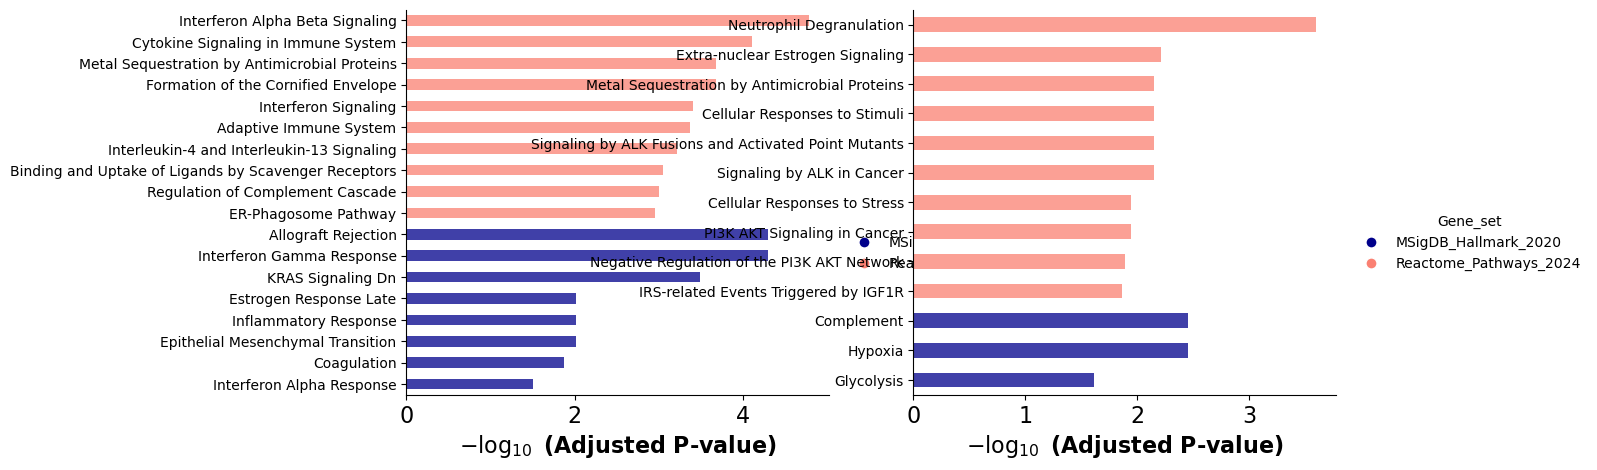

In [54]:
fig, axes = plt.subplots( 1, 2, figsize=(12,5))
# categorical scatterplot
ax = gp.barplot(signif_cd45,
              column="Adjusted P-value",
              group='Gene_set', # set group, so you could do a multi-sample/library comparsion
              size=10,
              top_term=10,
              figsize=(3,5),
              color = {'Reactome_Pathways_2024': 'salmon', 'MSigDB_Hallmark_2020':'darkblue'},
            ax=axes[0]
            )

ax = gp.barplot(signif_panck,
              column="Adjusted P-value",
              group='Gene_set', # set group, so you could do a multi-sample/library comparsion
              size=10,
              top_term=10,
              figsize=(3,5),
              color = {'Reactome_Pathways_2024': 'salmon', 'MSigDB_Hallmark_2020':'darkblue'},
            ax=axes[1]
            )

axes[0].tick_params(axis='y', labelsize=10)
axes[1].tick_params(axis='y', labelsize=10)
plt.show()

## PanCK

In [55]:
signif_panck.shape

(62, 10)

In [56]:
cond = signif_panck['Gene_set'].isin(['MSigDB_Hallmark_2020'])
signif_panck.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].head()

,Gene_set,Term,Adjusted P-value,Genes
0,MSigDB_Hallmark_2020,Hypoxia,0.003536,BCL2;MIF;ENO1;ALDOA;EGFR
1,MSigDB_Hallmark_2020,Complement,0.003536,ZEB1;PIK3CA;CXCL1;S100A9;LTF
2,MSigDB_Hallmark_2020,Glycolysis,0.024227,MIF;ENO1;ALDOA;EGFR


In [57]:
cond = signif_panck['Gene_set'].isin(['Reactome_Pathways_2024'])
signif_panck.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].head(20)

,Gene_set,Term,Adjusted P-value,Genes
35,Reactome_Pathways_2024,Neutrophil Degranulation,0.000254,PIGR;ATP8A1;FTH1;CXCL1;S100P;MIF;ALDOA;S100A9;...
38,Reactome_Pathways_2024,Extra-nuclear Estrogen Signaling,0.006142,PIK3CA;BCL2;STRN;EGFR
39,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,0.007117,S100A9;LTF
40,Reactome_Pathways_2024,Cellular Responses to Stimuli,0.007117,RB1;AR;PIK3CA;RPL12;BCL2;CA9;BRCA1;H1-0;HSPA1B...
41,Reactome_Pathways_2024,Signaling by ALK Fusions and Activated Point M...,0.007117,RB1;CCNB1;PIK3CA;STRN
42,Reactome_Pathways_2024,Signaling by ALK in Cancer,0.007117,RB1;CCNB1;PIK3CA;STRN
43,Reactome_Pathways_2024,PI3K AKT Signaling in Cancer,0.011504,PIK3CA;PTEN;STRN;EGFR
44,Reactome_Pathways_2024,Cellular Responses to Stress,0.011504,RB1;AR;RPL12;BCL2;CA9;BRCA1;H1-0;HSPA1B;RPS12
45,Reactome_Pathways_2024,Negative Regulation of the PI3K AKT Network,0.012943,PIK3CA;PTEN;STRN;EGFR
46,Reactome_Pathways_2024,IRS-related Events Triggered by IGF1R,0.013704,PIK3CA;IRS4;IGF2


In [58]:
signif_panck.to_csv(os.path.join(output_path,'SignificantPathways_PanCK_nocontamination.csv'))

## Single FM only

In [ ]:
COMPARE_SINGLE=False

In [ ]:
if COMPARE_SINGLE:
    results_cd45_single={}
    results_panck_single={}

In [ ]:
# for lib in libraries:
#     print(lib)
#     best_cd45_df_single, worst_cd45_df_single=check_genesets(best_genes_cd45_virchow,worst_genes_cd45_virchow, lib)
#     best_panck_df_single, worst_panck_df_single=check_genesets(best_genes_panck_uni,worst_genes_panck_uni, lib,segment='PanCK+')
#     results_cd45_single[(lib, 'best')]=best_cd45_df_single
#     results_cd45_single[(lib, 'worst')]=worst_cd45_df_single
#     results_panck_single[(lib, 'best')]=best_panck_df_single
#     results_panck_single[(lib, 'worst')]=worst_panck_df_single

MSigDB_Hallmark_2020
Reactome_Pathways_2024


In [ ]:
if COMPARE_SINGLE:
    signif_cd45_single_list=[]
    signif_panck_single_list=[]
    for lib in libraries:
        tmp = results_cd45_single[(lib, 'best')]
        signif_cd45_single_list.append(tmp[tmp['Adjusted P-value']<0.05])
        tmp = results_panck_single[(lib, 'best')]
        signif_panck_single_list.append(tmp[tmp['Adjusted P-value']<0.05])

### CD45

In [ ]:
if COMPARE_SINGLE:
    signif_cd45_single = pd.concat(signif_cd45_single_list).sort_values('Adjusted P-value')
    signif_cd45_single.shape

(107, 10)

In [ ]:
if COMPARE_SINGLE:
    cond = signif_cd45_single['Gene_set'].isin(['MSigDB_Hallmark_2020'])
    signif_cd45_single.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].iloc[0:15]

,Gene_set,Term,Adjusted P-value,Genes
0,MSigDB_Hallmark_2020,Allograft Rejection,0.000065,CD4;CXCL9;IFNG;STAT1;CD8A;CD3D;TAPBP;HLA-E
1,MSigDB_Hallmark_2020,Interferon Gamma Response,0.000065,CD274;CXCL9;STAT1;MX1;HLA-B;ISG15;TAPBP;IDO1
2,MSigDB_Hallmark_2020,KRAS Signaling Dn,0.000405,CPB1;IFNG;CALML5;KRT15;MX1;KRT5;TENT5C
3,MSigDB_Hallmark_2020,Estrogen Response Late,0.002445,SERPINA3;BCL2;TPSAB1;S100A9;CXCL14;AREG
4,MSigDB_Hallmark_2020,Coagulation,0.002580,MMP11;MMP7;MMP1;S100A1;APOC1
5,MSigDB_Hallmark_2020,Epithelial Mesenchymal Transition,0.009553,COL1A1;SFRP1;MMP1;ELN;AREG
6,MSigDB_Hallmark_2020,Inflammatory Response,0.009553,CCL24;CXCL9;IFITM1;CD82;TAPBP
7,MSigDB_Hallmark_2020,Interferon Alpha Response,0.034239,IFITM1;MX1;ISG15


In [ ]:
if COMPARE_SINGLE:
    cond = signif_cd45_single['Gene_set'].isin(['Reactome_Pathways_2024'])
    signif_cd45_single.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].iloc[0:15]

,Gene_set,Term,Adjusted P-value,Genes
0,Reactome_Pathways_2024,Immune System,5.341555e-08,SERPINA3;IGHM;CD274;IFITM1;CALML5;IFI6;CD3D;IG...
1,Reactome_Pathways_2024,Interferon Alpha Beta Signaling,2.116932e-05,IFITM1;STAT1;MX1;HLA-B;IFI6;ISG15;HLA-E
2,Reactome_Pathways_2024,Innate Immune System,6.452405e-05,SERPINA3;CALML5;MUCL1;S100A1;HLA-B;ISG15;HLA-E...
3,Reactome_Pathways_2024,Cytokine Signaling in Immune System,9.267104e-05,IFITM1;MMP1;STAT1;MX1;IFI6;HLA-B;UBE2E1;ISG15;...
4,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,1.908901e-04,LCN2;S100A9;S100A7
5,Reactome_Pathways_2024,Formation of the Cornified Envelope,2.188752e-04,KRT17;KRT15;KRT14;KRT7;KRT23;KRT5;KRT6A
6,Reactome_Pathways_2024,Degradation of the Extracellular Matrix,3.229739e-04,COL1A1;MMP11;MMP7;ADAM15;MMP1;ELN;TPSAB1
7,Reactome_Pathways_2024,Interferon Signaling,4.574381e-04,IFITM1;IFNG;STAT1;MX1;IFI6;HLA-B;UBE2E1;ISG15;...
9,Reactome_Pathways_2024,Adaptive Immune System,5.890062e-04,IGHM;CD274;LAG3;IFITM1;S100A1;HLA-B;UBE2E1;CD3...
8,Reactome_Pathways_2024,Infectious Disease,5.890062e-04,IGHM;CD163;RPL41;STAT1;RPLP1;HLA-B;ISG15;HLA-E...


In [ ]:
if COMPARE_SINGLE:
    signif_cd45_single.to_csv(os.path.join(output_path,'SignificantPathways_CD45_single_nocontam.csv'))

### PanCK

In [ ]:
if COMPARE_SINGLE:
    signif_panck_single = pd.concat(signif_panck_single_list).sort_values('Adjusted P-value')
    signif_panck_single.shape

(56, 10)

In [ ]:
if COMPARE_SINGLE:
    cond = signif_panck_single['Gene_set'].isin(['TISSUES_Curated_2025'])
    signif_panck_single.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].iloc[0:15]

,Gene_set,Term,Adjusted P-value,Genes


In [ ]:
if COMPARE_SINGLE:
    cond = signif_panck_single['Gene_set'].isin(['MSigDB_Hallmark_2020'])
    signif_panck_single.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].iloc[0:15]

,Gene_set,Term,Adjusted P-value,Genes
0,MSigDB_Hallmark_2020,Hypoxia,0.019012,ENO1;ALDOA;EGFR
4,MSigDB_Hallmark_2020,Allograft Rejection,0.019012,BRCA1;MMP9;EGFR
3,MSigDB_Hallmark_2020,Glycolysis,0.019012,ENO1;ALDOA;EGFR
2,MSigDB_Hallmark_2020,Complement,0.019012,PIK3CA;CXCL1;LTF
1,MSigDB_Hallmark_2020,Apical Junction,0.019012,PTEN;MMP9;EGFR


In [ ]:
if COMPARE_SINGLE:    
    cond = signif_panck_single['Gene_set'].isin(['Reactome_Pathways_2024'])
    signif_panck_single.loc[cond,['Gene_set','Term','Adjusted P-value','Genes']].iloc[10:25]

,Gene_set,Term,Adjusted P-value,Genes
9,Reactome_Pathways_2024,Constitutive Signaling by Ligand-Responsive EG...,0.011159,PIK3CA;EGFR
10,Reactome_Pathways_2024,Impaired BRCA2 Binding to PALB2,0.011159,BRCA1;BRCA2
11,Reactome_Pathways_2024,PI3K AKT Signaling in Cancer,0.011159,PIK3CA;PTEN;EGFR
20,Reactome_Pathways_2024,Gluconeogenesis,0.011159,ENO1;ALDOA
13,Reactome_Pathways_2024,Signaling by ERBB2 KD Mutants,0.011159,PIK3CA;EGFR
14,Reactome_Pathways_2024,Defective HDR Through Homologous Recombination...,0.011159,BRCA1;BRCA2
15,Reactome_Pathways_2024,Defective HDR Through Homologous Recomb Repair...,0.011159,BRCA1;BRCA2
16,Reactome_Pathways_2024,Defective Homologous Recombination Repair (HRR...,0.011159,BRCA1;BRCA2
17,Reactome_Pathways_2024,Defective Homologous Recombination Repair (HRR...,0.011159,BRCA1;BRCA2
18,Reactome_Pathways_2024,Signaling by Nuclear Receptors,0.011159,PIK3CA;ALDH1A1;MMP9;EGFR


In [ ]:
if COMPARE_SINGLE:
    signif_panck_single.to_csv(os.path.join(output_path,'SignificantPathways_PanCK_single_no-contam.csv'))

## Compare Single with Combined

### CD45

### PanCK

In [ ]:
if COMPARE_SINGLE:
    signif_panck.sort_values('Odds Ratio',ascending=False).head()
    signif_panck_single.sort_values('Odds Ratio',ascending=False).head()

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
3,Reactome_Pathways_2024,Signaling by EGFRvIII in Cancer,2/15,0.000226,0.011159,0,0,109.653846,920.723866,PIK3CA;EGFR
4,Reactome_Pathways_2024,Constitutive Signaling by EGFRvIII,2/15,0.000226,0.011159,0,0,109.653846,920.723866,PIK3CA;EGFR
5,Reactome_Pathways_2024,Signaling by ERBB2 ECD Mutants,2/16,0.000258,0.011159,0,0,101.816327,841.414239,PIK3CA;EGFR
6,Reactome_Pathways_2024,PI3K Events in ERBB2 Signaling,2/16,0.000258,0.011159,0,0,101.816327,841.414239,PIK3CA;EGFR
7,Reactome_Pathways_2024,GAB1 Signalosome,2/17,0.000292,0.011159,0,0,95.023810,773.475674,PIK3CA;EGFR


In [ ]:
if COMPARE_SINGLE:
    signif_panck_single['Adjusted P-value'].max()

0.0491866810892071

In [ ]:
if COMPARE_SINGLE:
    in_combined = list(set(signif_panck['Term']).difference(set(signif_panck_single['Term'])))
    signif_panck[signif_panck['Term'].isin(in_combined)].sort_values('Odds Ratio',ascending=False)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
39,Reactome_Pathways_2024,Metal Sequestration by Antimicrobial Proteins,2/6,0.000107,0.007117,0,0,191.750000,1753.856190,S100A9;LTF
55,Reactome_Pathways_2024,Formation of Senescence-Associated Heterochrom...,2/17,0.000948,0.020325,0,0,51.105128,355.743323,RB1;H1-0
62,Reactome_Pathways_2024,Signaling by PDGFR in Disease,2/20,0.001318,0.022517,0,0,42.581197,282.391215,PIK3CA;STRN
65,Reactome_Pathways_2024,E2F Mediated Regulation of DNA Replication,2/22,0.001597,0.023554,0,0,38.319231,246.771732,RB1;CCNB1
66,Reactome_Pathways_2024,Regulation of Signaling by CBL,2/22,0.001597,0.023554,0,0,38.319231,246.771732,PIK3CA;BLNK
70,Reactome_Pathways_2024,Estrogen-dependent Nuclear Events Downstream o...,2/24,0.001901,0.023554,0,0,34.832168,218.236267,BCL2;EGFR
69,Reactome_Pathways_2024,RUNX2 Regulates Osteoblast Differentiation,2/24,0.001901,0.023554,0,0,34.832168,218.236267,RB1;AR
85,Reactome_Pathways_2024,Signaling by ALK,2/30,0.002965,0.028548,0,0,27.359890,159.255952,CD274;PIK3CA
84,Reactome_Pathways_2024,Activation of BH3-only Proteins,2/30,0.002965,0.028548,0,0,27.359890,159.255952,BCL2;TP63
86,Reactome_Pathways_2024,RUNX2 Regulates Bone Development,2/31,0.003164,0.029879,0,0,26.415119,152.040576,RB1;AR


In [ ]:

if COMPARE_SINGLE:
    in_single = list(set(signif_panck_single['Term']).difference(set(signif_panck['Term'])))
    signif_panck_single[signif_panck_single['Term'].isin(in_single)].head()

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
2,Reactome_Pathways_2024,Innate Immune System,8/1149,0.000218,0.011159,0,0,6.000797,50.601928,PIK3CA;FTH1;CHI3L1;S100P;CXCL1;ALDOA;MMP9;LTF
24,Reactome_Pathways_2024,Immune System,10/2150,0.000799,0.011159,0,0,4.165888,29.709873,RNF126;PIK3CA;FTH1;PTEN;CHI3L1;S100P;CXCL1;ALD...
4,MSigDB_Hallmark_2020,Allograft Rejection,3/200,0.003278,0.019012,0,0,11.152284,63.796903,BRCA1;MMP9;EGFR
1,MSigDB_Hallmark_2020,Apical Junction,3/200,0.003278,0.019012,0,0,11.152284,63.796903,PTEN;MMP9;EGFR
32,Reactome_Pathways_2024,Signaling by SCF-KIT,2/43,0.001890,0.019405,0,0,34.719512,217.724534,PIK3CA;MMP9


# Figure

terms from each library

get top 10 pathways - aiming for 5 from each

In [ ]:
numterms = 5
sort_field = 'Adjusted P-value'
ascend = True

In [ ]:
cd45_subset = pd.concat([signif_cd45[signif_cd45['Gene_set']=='MSigDB_Hallmark_2020'].sort_values(sort_field,ascending=ascend)[:(numterms)],
                        signif_cd45[signif_cd45['Gene_set']=='Reactome_Pathways_2024'].sort_values(sort_field,ascending=ascend)[:numterms]])

In [ ]:
num_msig_pck = signif_panck[signif_panck['Gene_set']=='MSigDB_Hallmark_2020'].shape[0]

In [ ]:
# panck_subset = pd.concat([signif_panck[signif_panck['Gene_set']=='MSigDB_Hallmark_2020'].sort_values(sort_field,ascending=ascend)[:num_msig_pck],
#                         signif_panck[signif_panck['Gene_set']=='Reactome_Pathways_2024'].sort_values(sort_field,ascending=ascend)[:(numterms*2)-num_msig_pck]])

In [ ]:
panck_subset = pd.concat([signif_panck[signif_panck['Gene_set']=='MSigDB_Hallmark_2020'].sort_values('Adjusted P-value')[:numterms],
                        signif_panck[signif_panck['Gene_set']=='Reactome_Pathways_2024'].sort_values('Adjusted P-value')[:numterms]])

sort by FDR adjusted p-value

In [80]:

cd45_subset["minus_log10FDR"] = -np.log10(cd45_subset['Adjusted P-value'])
panck_subset["minus_log10FDR"] = -np.log10(panck_subset['Adjusted P-value'])
cd45_subset = cd45_subset.sort_values("minus_log10FDR", ascending=True)
panck_subset = panck_subset.sort_values("minus_log10FDR", ascending=True)

tidy up for display

In [81]:
cd45_subset.loc[:,'Gene_set'] = cd45_subset['Gene_set'].replace({
    'MSigDB_Hallmark_2020': 'MSigDB Hallmark 2020',   'Reactome_Pathways_2024': 'Reactome Pathways 2024'})
panck_subset.loc[:,'Gene_set'] = panck_subset['Gene_set'].replace({
    'MSigDB_Hallmark_2020': 'MSigDB Hallmark 2020',   'Reactome_Pathways_2024': 'Reactome Pathways 2024'})

In [82]:
import seaborn as sns

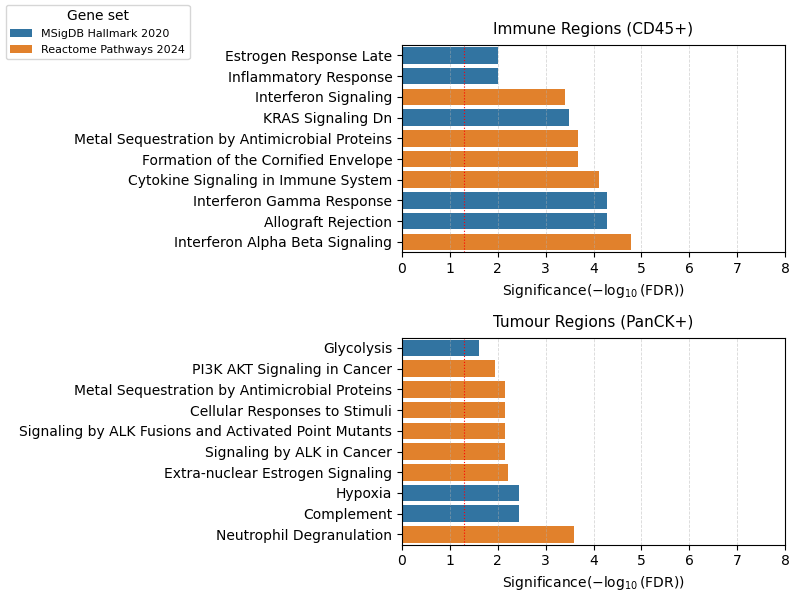

In [83]:
fig, axes = plt.subplots(2,1, figsize=(8, 6))

for i,df in enumerate([cd45_subset, panck_subset]):
    sns.barplot(
        data=df,
        x="minus_log10FDR",
        y="Term",
        hue="Gene_set", 
        hue_order=['MSigDB Hallmark 2020', 'Reactome Pathways 2024'],
        ax = axes[i]
    )
    # Title

    # Axis labels
    axes[i].set_xlabel(r"Significance($-\log_{10}(\mathrm{FDR})$)", fontsize=10)
    axes[i].set_ylabel("")  # remove default y-axis label

    # Make y-tick labels smaller for journal fit
    axes[i].tick_params(axis="y", labelsize=10)

    # Gridlines only on x-axis
    axes[i].grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.5)
    axes[i].set_xlim((0,8))
    axes[i].axvline(-np.log10(0.05), linestyle=":", linewidth=0.8, color="red")

axes[0].set_title("Immune Regions (CD45+)", fontsize=11, pad=8)
axes[1].set_title("Tumour Regions (PanCK+)", fontsize=11, pad=8)


# Create a single legend from the first axes
handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(handles, labels, title="Gene set", 
                    fontsize=8,
                    loc="center left", 
                    frameon=True)
legend.set_bbox_to_anchor((0, .95))

axes[0].get_legend().remove()
axes[1].get_legend().remove()
plt.tight_layout()#rect=[0, 0, 1, 1])
plt.show()

Table for pathway enrichment

In [84]:
cd45_subset['segment']='CD45+'
panck_subset['segment']='PanCK+'

In [85]:
panck_subset

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,minus_log10FDR,segment
2,MSigDB Hallmark 2020,Glycolysis,4/200,2.076593e-03,0.024227,0,0,8.061224,49.794398,MIF;ENO1;ALDOA;EGFR,1.615702,PanCK+
43,Reactome Pathways 2024,PI3K AKT Signaling in Cancer,4/110,2.216581e-04,0.011504,0,0,14.973585,125.993348,PIK3CA;PTEN;STRN;EGFR,1.939133,PanCK+
39,Reactome Pathways 2024,Metal Sequestration by Antimicrobial Proteins,2/6,1.065840e-04,0.007117,0,0,191.750000,1753.856190,S100A9;LTF,2.147679,PanCK+
40,Reactome Pathways 2024,Cellular Responses to Stimuli,10/887,1.134091e-04,0.007117,0,0,4.941692,44.892842,RB1;AR;PIK3CA;RPL12;BCL2;CA9;BRCA1;H1-0;HSPA1B...,2.147679,PanCK+
41,Reactome Pathways 2024,Signaling by ALK Fusions and Activated Point M...,4/93,1.159657e-04,0.007117,0,0,17.848989,161.751397,RB1;CCNB1;PIK3CA;STRN,2.147679,PanCK+
42,Reactome Pathways 2024,Signaling by ALK in Cancer,4/93,1.159657e-04,0.007117,0,0,17.848989,161.751397,RB1;CCNB1;PIK3CA;STRN,2.147679,PanCK+
38,Reactome Pathways 2024,Extra-nuclear Estrogen Signaling,4/75,5.004016e-05,0.006142,0,0,22.394366,221.764349,PIK3CA;BCL2;STRN;EGFR,2.211660,PanCK+
0,MSigDB Hallmark 2020,Hypoxia,5/200,2.020829e-04,0.003536,0,0,10.335426,87.921744,BCL2;MIF;ENO1;ALDOA;EGFR,2.451432,PanCK+
1,MSigDB Hallmark 2020,Complement,5/200,2.020829e-04,0.003536,0,0,10.335426,87.921744,ZEB1;PIK3CA;CXCL1;S100A9;LTF,2.451432,PanCK+
35,Reactome Pathways 2024,Neutrophil Degranulation,10/478,5.162980e-07,0.000254,0,0,9.459013,136.934178,PIGR;ATP8A1;FTH1;CXCL1;S100P;MIF;ALDOA;S100A9;...,3.596018,PanCK+


In [ ]:
df = pd.concat([cd45_subset.sort_values(sort_field,ascending=ascend),panck_subset.sort_values(sort_field,ascending=ascend)])
df = df[['segment','Gene_set','Term','Overlap','P-value','Adjusted P-value','Odds Ratio','Genes']]


In [ ]:
df.to_csv(os.path.join(output_path,f'SignificantPathways_combined_{sort_field}.csv'))

In [ ]:
df = df.drop(columns=["Overlap","Genes"])
df.head()

In [ ]:
df = df.sort_values(['segment','Gene_set','Adjusted P-value'],ascending=ascend)

In [ ]:
table_path = "C:/Users/hooll/Dropbox/19 PostGrad/00 CB Lab/01 projects/06 MultiModal/paper/01 revisions/tables"
df.to_csv(os.path.join(table_path,'pathways.csv'), index=False)

These are the genes to enter into cancerhallmarks.com

In [88]:
for gene in top_genes_cd45:
    print(gene)

ST6GALNAC3
PRMT8
FDCSP
C7
AREG
PITX1
TARP
CCSAP
TENT5C
USP17L3
CPB1
RPL41
BCL2
CD8A
UBE2E1
P2RY12
IDO1
CD274
DMRTC1B
EYA2


In [89]:
for gene in top_genes_panck:
    print(gene)

BRCA1
ENO1
S100A2
BRCA2
NWD2
ATP5MC2
SNAI1
CSN3
BCL2
MIF
CD274
BRINP3
PIK3CA
PIGR
S100P
DMRTB1
PTEN
C11orf58
CPB1
MKI67


# Get Images from cancerhallmarks.com

In [90]:
from PIL import Image
import matplotlib.pyplot as plt

used all genes with R2>0.2, PCC>0.5 and qval < 0.05>

combined-svm-genescores.csv?
genesetgoodmodels.csv?

In [ ]:
#
cols = ['Segment','Gene','R2','PearsonCorr','PearsonQVals','PearsonCI_low', 'PearsonCI_high','SpearmanCorr','ConcordanceCorr' ]
#geneset_good_models = pd.read_csv(os.path.join(input_path,'genesetgoodmodels.csv'), index_col=0)

geneset_good_models = pd.read_csv(os.path.join(summary_path,folder_name,'genesetgoodmodels.csv'), index_col=0)
geneset_good_models = geneset_good_models[cols]
geneset_good_models.sort_values('ConcordanceCorr',ascending=False).head(20)

,Segment,Gene,R2,PearsonCorr,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,ConcordanceCorr
Column1,,,,,,,,,
87.0,CD45+,FDCSP,0.726414,0.864334,4.920000e-38,0.812936,0.902371,0.809385,0.827602
72.0,CD45+,ST6GALNAC3,0.724390,0.878739,6.460000e-41,0.832307,0.912926,0.816000,0.809220
94.0,CD45+,TARP,0.684002,0.832331,2.400000e-33,0.770301,0.878757,0.803136,0.807123
69.0,CD45+,AREG,0.696395,0.854655,1.420000e-36,0.799983,0.895253,0.796541,0.792812
15.0,CD45+,PRMT8,0.687381,0.871958,8.190000e-40,0.823174,0.907963,0.865628,0.784521
97.0,CD45+,CD8A,0.600483,0.797285,8.840000e-29,0.724241,0.852634,0.793786,0.772511
62.0,CD45+,C7,0.677028,0.863621,2.280000e-38,0.811979,0.901847,0.804464,0.766855
45.0,CD45+,USP17L3,0.656838,0.826062,1.250000e-32,0.762014,0.874104,0.804293,0.762610
106.0,CD45+,CCSAP,0.643177,0.829390,5.480000e-33,0.766411,0.876575,0.799190,0.759361


check which genes do not meet all thresholds

In [93]:
cond = (
        (geneset_good_models['R2']>0.2) &
        (geneset_good_models['PearsonQVals']<0.05) &
        (geneset_good_models['PearsonCorr']>0.5)
    )
print(f"{geneset_good_models[~cond].shape[0]} genes do not meet the thresholds")
geneset_good_models[~cond]

4 genes do not meet the thresholds


,Segment,Gene,R2,PearsonCorr,PearsonQVals,PearsonCI_low,PearsonCI_high,SpearmanCorr,ConcordanceCorr
Column1,,,,,,,,,
236.0,PanCK+,CMPK1,0.225111,0.487240,6.690000e-11,0.360522,0.596298,0.496856,0.352446
207.0,PanCK+,H1-0,0.238628,0.495866,2.860000e-11,0.370378,0.603579,0.505268,0.354247
212.0,PanCK+,STRN,0.218746,0.475129,2.180000e-10,0.346733,0.586047,0.496947,0.403813
110.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
os.makedirs(os.path.join(output_path,'cancerhallmarks','genelists',folder_name), exist_ok=True)

In [94]:
genes_to_use = geneset_good_models[cond]

examine the top by PCC

In [ ]:
filename = os.path.join(output_path,'cancerhallmarks','genelists',folder_name,"cd45_R202_PCC05.txt")
with open(filename, "w", encoding="utf-8") as f:
    f.write(
        "\n".join(
            genes_to_use.loc[genes_to_use['Segment'] == 'CD45+']
            .sort_values('PearsonCorr', ascending=False)['Gene']
        )
    )

In [ ]:
filename = os.path.join(output_path,'cancerhallmarks','genelists',folder_name,"panck_R202_PCC05.txt")
with open(filename, "w", encoding="utf-8") as f:
    f.write(
        "\n".join(
            genes_to_use.loc[genes_to_use['Segment'] == 'PanCK+']
            .sort_values('PearsonCorr', ascending=False)['Gene']
        )
    )

In [ ]:
filename = os.path.join(output_path,'cancerhallmarks','genelists',folder_name,"all_R202_PCC05.txt")
with open(filename, "w", encoding="utf-8") as f:
    f.write(
        "\n".join(
            genes_to_use.sort_values('PearsonCorr', ascending=False)['Gene']
        )
    )

Up the threshold for R2

In [ ]:
R2_thresholds = [0.2,0.3,0.4]
PCC_thresholds = [0.1,0.5]
qval_thresh = 0.05
filepath = os.path.join(output_path,'cancerhallmarks','genelists',folder_name)
os.makedirs(filepath, exist_ok=True)

for R2_thresh in R2_thresholds:
    for PCC_thresh in PCC_thresholds:
        cond =  (
            (geneset_good_models['R2']>R2_thresh) &
            (geneset_good_models['PearsonQVals']<qval_thresh) &
            (geneset_good_models['PearsonCorr']>PCC_thresh)
        )
        print(f"{geneset_good_models[~cond].shape[0]} genes do not meet the threshold: R2 {R2_thresh} PCC {PCC_thresh}")
        genes_to_use = geneset_good_models.loc[cond].sort_values('PearsonCorr', ascending=False)

        R2_tag = f"{int(R2_thresh * 10):02d}"
        PCC_tag = f"{int(PCC_thresh * 10):02d}"
        with open(os.path.join(filepath,f"genes_R2{R2_tag}_PCC{PCC_tag}_all.txt"), "w", encoding="utf-8") as f:
            f.write("\n".join(genes_to_use['Gene'] ))
        
        with open(os.path.join(filepath,f"genes_R2{R2_tag}_PCC{PCC_tag}_cd45.txt"), "w", encoding="utf-8") as f:
            f.write(
                "\n".join( genes_to_use.loc[genes_to_use['Segment'] == 'CD45+','Gene'])
            )

        with open(os.path.join(filepath,f"genes_R2{R2_tag}_PCC{PCC_tag}_panck.txt"), "w", encoding="utf-8") as f:
            f.write(
                "\n".join( genes_to_use.loc[genes_to_use['Segment'] == 'PanCK+','Gene'])
            )

1 genes do not meet the threshold: R2 0.2 PCC 0.1
4 genes do not meet the threshold: R2 0.2 PCC 0.5
46 genes do not meet the threshold: R2 0.3 PCC 0.1
46 genes do not meet the threshold: R2 0.3 PCC 0.5
79 genes do not meet the threshold: R2 0.4 PCC 0.1
79 genes do not meet the threshold: R2 0.4 PCC 0.5


## Examine full scores

In [99]:
#geneset_good_models = pd.read_csv(os.path.join(summary_path,'genesetgoodmodels.csv'))
cols = ['Segment','GeneSet','Gene','R2','PearsonCorr','ConcordanceCorr','PearsonQVals']#,'ConcordanceCorr_calib']
full_genescores = pd.read_csv(os.path.join(input_path,'combined-svm-genescores.csv'))
#full_genescores = full_genescores[cols]
full_genescores.head()

,Average of PearsonCorr,Column Labels,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,Row Labels,Panel,HVG,SVG,Grand Total
1,CD45+,0.74,0.63,0.74,0.68
2,PanCK+,0.53,0.44,0.51,0.48
3,Grand Total,0.61,0.54,0.62,0.58


In [ ]:
for segment in ['CD45+','PanCK+']:
    for geneset in ['HVG','SVG']:
        cond = (
            (full_genescores['Segment']==segment) &
            (full_genescores['GeneSet']==geneset)
        )
        with open(os.path.join(filepath,f"genes_{geneset}_{segment}.txt"), "w", encoding="utf-8") as f:
            f.write("\n".join(full_genescores.loc[cond,'Gene']))

In [ ]:
for geneset in ['HVG','SVG']:
    cond = (full_genescores['GeneSet']==geneset)
    with open(os.path.join(filepath,f"genes_{geneset}_all.txt"), "w", encoding="utf-8") as f:
        f.write("\n".join(full_genescores.loc[cond,'Gene']))

In [ ]:
cond = (
    (full_genescores['Segment']=='CD45+') 
)
" ".join(full_genescores.loc[cond,'Gene'])

In [ ]:
" ".join(full_genescores['Gene'])

In [ ]:
for gene in list(all_scores.Gene.unique()):
    print(gene) 

len(all_scores[all_scores['Segment']=='CD45+'])

In [ ]:
for segment in ['CD45+','PanCK+']:
    cond = (
        (full_genescores['Segment']==segment) 
    )
    with open(os.path.join(filepath,f"0{segment[:-1].lower()}_allgenes.txt"), "w", encoding="utf-8") as f:
        f.write("\n".join(full_genescores.loc[cond,'Gene']))

In [ ]:
with open(os.path.join(filepath,f"0allgenes.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(full_genescores.loc[:,'Gene']))

## Read pics

In [ ]:
def show_hallmarks(img_cd45, img_panck, img_all, title='Hallmarks of Cancer'):
    fig, axes = plt.subplots(1, 3, figsize=(12, 5))#, constrained_layout=True)
    axes[0].imshow(img_cd45)
    axes[0].set_title("Immune Regions (CD45+)")
    axes[0].axis("off")

    axes[1].imshow(img_panck)
    axes[1].set_title("Tumour Regions (PanCK+)")
    axes[1].axis("off")


    axes[2].imshow(img_all)
    axes[2].set_title("Immune and Tumour Combined")
    axes[2].axis("off")

    fig.suptitle(title, fontsize=16)
    #plt.tight_layout(pad=0.1) 
    #plt.subplots_adjust(wspace=0.002) 
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0.0002, hspace=0.0002)
    plt.show()

### From Core Cancer Hallmark Gene Set n=1574
genes appear in at least 2 sources

In [ ]:
img_path = os.path.join(output_path,'cancerhallmarks','figures',folder_name,'with distribution plots','2-core_cancer_hallmark_gene_set_n1574')
cancerhallmarks_img_cd45 = Image.open(os.path.join(img_path,"0cd45_allgenes-2.png"))
cancerhallmarks_img_panck = Image.open(os.path.join(img_path,"0panck_allgenes-2.png"))
cancerhallmarks_img_all = Image.open(os.path.join(img_path,"0allgenes-2.png"))

In [ ]:
cancerhallmarks_img_cd45_robust =  Image.open(os.path.join(img_path,"genes_R202_PCC05_cd45-2.png"))
cancerhallmarks_img_panck_robust = Image.open(os.path.join(img_path,"genes_R202_PCC05_panck-2.png"))
cancerhallmarks_img_all_robust =  Image.open(os.path.join(img_path,"genes_R202_PCC05_all-2.png"))

In [ ]:
show_hallmarks(cancerhallmarks_img_cd45,cancerhallmarks_img_panck,cancerhallmarks_img_all)

In [ ]:
show_hallmarks(cancerhallmarks_img_cd45_robust,cancerhallmarks_img_panck_robust,cancerhallmarks_img_all_robust, title='Robustly predicted genes')

### From Integrated Cancer Hallmark Gene Set n=6763

genes appear in at least 1 source

In [ ]:
img_path = os.path.join(output_path,'cancerhallmarks','figures',folder_name,'with distribution plots','1-integrated_cancer_hallmark_gene_set_n6763')
cancerhallmarks_img_cd45 = Image.open(os.path.join(img_path,"0cd45_allgenes-1.png"))
cancerhallmarks_img_panck = Image.open(os.path.join(img_path,"0panck_allgenes-1.png"))
cancerhallmarks_img_all = Image.open(os.path.join(img_path,"0allgenes-1.png"))

In [ ]:
cancerhallmarks_img_cd45_robust =  Image.open(os.path.join(img_path,"genes_R202_PCC05_cd45-1.png"))
cancerhallmarks_img_panck_robust = Image.open(os.path.join(img_path,"genes_R202_PCC05_panck-1.png"))
cancerhallmarks_img_all_robust =  Image.open(os.path.join(img_path,"genes_R202_PCC05_all-1.png"))
cancerhallmarks_img_cd45_r2 =  Image.open(os.path.join(img_path,"genes_R202_PCC01_cd45-1.png"))
cancerhallmarks_img_panck_r2 = Image.open(os.path.join(img_path,"genes_R202_PCC01_panck-1.png"))
cancerhallmarks_img_all_r2 =  Image.open(os.path.join(img_path,"genes_R202_PCC01_all-1.png"))

In [ ]:
show_hallmarks(cancerhallmarks_img_cd45,cancerhallmarks_img_panck,cancerhallmarks_img_all)

In [ ]:
show_hallmarks(cancerhallmarks_img_cd45_robust,cancerhallmarks_img_panck_robust,cancerhallmarks_img_all_robust, title='Robustly predicted genes')

In [ ]:
show_hallmarks(cancerhallmarks_img_cd45_r2,cancerhallmarks_img_panck_r2,cancerhallmarks_img_all_r2, title='R2 threshold met')

In [ ]:
geneset_good_models = pd.read_csv(os.path.join(root_path,'03-results_cv','summary','genesetgoodmodels.csv'),index_col=0)

In [ ]:
genes_of_interest=['ALDH1A1','AR','AREG','BCL2','BCL2','BRCA1','BRCA2','C7','CA9','CCNB1','CD163','CD274','CD274',
'CD3D','CD4','CD68','CD8A','CXCL1','CXCL14','CXCL9','EGFR','ENO1','FOXA1','FOXP3','IDO1','IFNG',
'IFNG','IGHG1','IGHG2','IGHG3','IGHG4','IGKC','LAG3','MKI67','MYC','PIK3CA','PTEN','RB1','S100A2',
'S100A9','SNAI1','SOX10','STAT1','TP63','ZEB1']

cols = ['Segment','Gene','nRMSE','R2','PearsonCorr','PearsonQVals','VarianceRatio','VarianceRatio_calib']

In [ ]:
stats_of_interest = geneset_good_models.loc[geneset_good_models['Gene'].isin(genes_of_interest),cols]

In [ ]:
stats_of_interest.to_csv(os.path.join(gene_path,'stats_of_interest.csv'))

# END